# Nivel II — Análisis estadístico de tolerancias (Monte Carlo en LTspice)
**Síntesis de Redes Activas — Filtro pasabajos Butterworth N = 3**

**Cómo usarlo en Google Colab**
1. Ejecutá las celdas en orden (Entorno > Ejecutar todo).
2. En la celda de carga, subí uno o más archivos .log generados por LTspice (uno por caso de tolerancia).
3. El notebook detecta solo las tolerancias de cada archivo, calcula estadísticas, cumplimiento de plantilla, histogramas y compara con la sensibilidad lineal.
4. Al final imprime filas de tablas listas para pegar en LaTeX y descarga un .zip con figuras y datos.

> Aclaración sobre el formato del log: LTspice imprime las medidas AC como números complejos, p. ej. (-0.43dB,0°). Los valores de m1k, m4k **y también los de los componentes (v_r3, v_c1, …)** vienen en dB; el parser los convierte a lineal con 10**(x/20).

In [39]:
import re, io, os, glob, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:.4g}")

## 1. Modelo del circuito y sensibilidad lineal

In [40]:
# Valores nominales comerciales (los del informe)
NOM  = dict(R3=11e3, C3=10e-9, R1=12e3, R2=12e3, C1=4.7e-9, C2=18e-9)
TIPO = dict(R3='R', R1='R', R2='R', C3='C', C1='C', C2='C')
COMP = list(NOM)

# Plantilla
A1K_MAX = 1.0    # dB, atenuacion maxima en 1 kHz
A4K_MIN = 24.0   # dB, atenuacion minima en 4 kHz

def H(f, p):
    """H_c(s) con operacionales ideales: 1er orden x Sallen-Key (K=1)."""
    s = 2j*np.pi*np.asarray(f, dtype=float)
    h1 = 1/(1 + s*p['R3']*p['C3'])
    h2 = 1/(1 + s*p['C1']*(p['R1']+p['R2']) + s**2*p['R1']*p['R2']*p['C1']*p['C2'])
    return h1*h2

def A1k(p): return -20*np.log10(abs(H(1e3, p)))
def A4k(p): return -20*np.log10(abs(H(4e3, p)))
def Ff3(p):
    lo, hi = 200.0, 5000.0
    for _ in range(60):
        mid = np.sqrt(lo*hi)
        if abs(H(mid, p)) > 10**(-3.0103/20): lo = mid
        else: hi = mid
    return mid

def sens_num(fun, h=1e-4):
    """S_x^y = (dy/dx)(x/y) por diferencias centradas."""
    y0 = fun(NOM); S = {}
    for k in COMP:
        pp, pm = dict(NOM), dict(NOM)
        pp[k] *= 1+h; pm[k] *= 1-h
        S[k] = (fun(pp) - fun(pm))/(2*h*y0)
    return S

def pred_lineal(fun, tolR, tolC):
    """sigma y peor caso (relativos a y0) por sensibilidad lineal, tolerancia uniforme."""
    S = sens_num(fun)
    tol = {k: (tolR if TIPO[k]=='R' else tolC) for k in COMP}
    sig = np.sqrt(sum((S[k]*tol[k]/np.sqrt(3))**2 for k in COMP))
    wc  = sum(abs(S[k])*tol[k] for k in COMP)
    return fun(NOM), sig*abs(fun(NOM)), wc*abs(fun(NOM)), S

print(f"Nominal: A(1k)={A1k(NOM):.3f} dB   A(4k)={A4k(NOM):.3f} dB   f-3dB={Ff3(NOM):.1f} Hz")

Nominal: A(1k)=0.571 dB   A(4k)=26.598 dB   f-3dB=1422.4 Hz


## 2. Lectura del `.log` de LTspice

In [41]:
def leer_log(path):
    """Devuelve {nombre_medida: array (un valor por corrida)}.
    Convierte '(x dB,0°)' -> lineal (10**(x/20)); los valores sin 'dB' quedan tal cual."""
    txt = open(path, errors="ignore").read()
    out = {}
    for b in re.split(r"Measurement:\s*", txt)[1:]:
        L = b.splitlines()
        nombre = L[0].strip().lower()
        v = {}
        for ln in L[1:]:
            m = re.match(r"\s*(\d+)\s+\(?([-+]?\d+\.?\d*(?:[eE][-+]?\d+)?)(dB)?", ln)
            if m:
                x = float(m.group(2))
                if m.group(3): x = 10**(x/20)
                v[int(m.group(1))] = x
        if v:
            out[nombre] = np.array([v[k] for k in sorted(v)])
    return out

def estimar_tol(d):
    """Estima la tolerancia sorteada a partir de los valores de componentes registrados."""
    def redondear(t):
        return min([0.005, 0.01, 0.02, 0.05, 0.10, 0.20], key=lambda c: abs(c - t))
    dev = lambda k: np.max(np.abs(d['v_'+k.lower()]/NOM[k] - 1))
    tR = redondear(max(dev(k) for k in COMP if TIPO[k]=='R'))
    tC = redondear(max(dev(k) for k in COMP if TIPO[k]=='C'))
    return tR, tC

## 3. Cargar los archivos `.log`
Subí los `.log` de LTspice (uno por caso). Si las tolerancias detectadas no son las correctas, indicalas a mano en `TOL_MANUAL`, por ejemplo `{"Filtro_MC.log": (0.05, 0.10)}`.

In [35]:
TOL_MANUAL = {}   # opcional: {"archivo.log": (tolR, tolC)}

try:
    from google.colab import files
    subidos = files.upload()
    for nombre, datos in subidos.items():
        with open(nombre, "wb") as f: f.write(datos)
    logs = list(subidos)
except ImportError:                         # fuera de Colab: usa los .log/.txt de la carpeta
    logs = sorted(glob.glob("*.log") + glob.glob("*.txt"))
print("Archivos:", logs)

Saving Filtro_MC.log to Filtro_MC (1).log
Archivos: ['Filtro_MC (1).log']


## 4. Análisis por caso

Filtro_MC (1).log  ->  R ±5%, C ±10%   (N = 500 corridas)
Combinaciones de componentes distintas: 500 de 500


,nominal,media MC,sigma MC,sigma lineal,sigma MC/lineal,min MC,max MC,max|desv| MC,peor caso lineal
magnitud,,,,,,,,,
A(1 kHz) [dB],0.5705,0.5859,0.292,0.2935,0.9951,-0.2581,1.343,0.8287,0.9882
A(4 kHz) [dB],26.6,26.61,0.9774,0.9709,1.007,24.08,29.19,2.588,3.89
f-3dB [Hz],1422,1421,66.07,66.61,0.992,1276,1603,180.8,218.5


Cumple A(1k) <= 1.0 dB :   92.8 %   (464/500)
Cumple A(4k) >= 24.0 dB:  100.0 %   (500/500)
Cumple AMBAS                :   92.8 %   (464/500)
IC 95 % (Wilson) del cumplimiento: [90.2 %, 94.8 %]


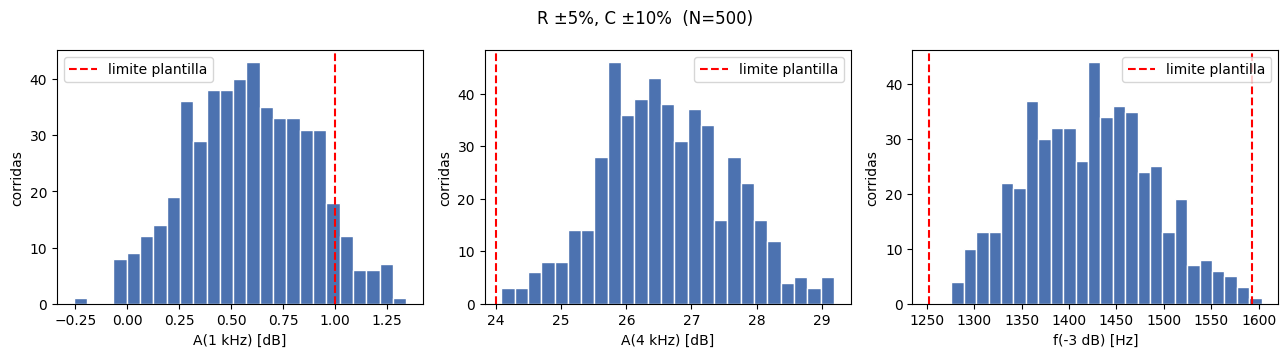


Sensibilidades: regresion sobre las corridas (S_reg) vs. analitica (S_num)


,S_reg A1k,S_num A1k,R2 A1k,S_reg A4k,S_num A4k,R2 A4k,S_reg f3dB,S_num f3dB,R2 f3dB
R3,5.057,4.921,0.9944,0.2881,0.2888,1,-0.3437,-0.3415,0.997
C3,4.9,4.921,0.9944,0.2887,0.2888,1,-0.343,-0.3415,0.997
R1,-0.005611,0.03002,0.9944,0.3434,0.3431,1,-0.3304,-0.3293,0.997
R2,0.2009,0.03002,0.9944,0.3421,0.3431,1,-0.3294,-0.3293,0.997
C1,4.996,4.985,0.9944,0.368,0.3679,1,-0.6764,-0.6764,0.997
C2,-4.813,-4.925,0.9944,0.3179,0.3183,1,0.02247,0.0179,0.997


In [36]:
def analizar(nombre, d, tR, tC):
    A1 = -20*np.log10(d['m1k'])      # atenuacion en 1 kHz [dB]
    A4 = -20*np.log10(d['m4k'])      # atenuacion en 4 kHz [dB]
    F3 = d['f3db']                   # frecuencia de -3 dB [Hz]
    N = len(A1)
    ok1, ok4 = A1 <= A1K_MAX, A4 >= A4K_MIN
    ok = ok1 & ok4
    etiqueta = f"R ±{tR*100:g}%, C ±{tC*100:g}%"

    print("="*78)
    print(f"{nombre}  ->  {etiqueta}   (N = {N} corridas)")
    # corridas efectivamente distintas
    if 'v_r3' in d:
        distintas = len({tuple(np.round(fila, 12)) for fila in
                         np.column_stack([d['v_'+k.lower()] for k in COMP])})
        print(f"Combinaciones de componentes distintas: {distintas} de {N}")
    print("="*78)

    # --- estadisticas + comparacion con sensibilidad lineal
    filas = []
    for nom, x, fun in [("A(1 kHz) [dB]", A1, A1k), ("A(4 kHz) [dB]", A4, A4k), ("f-3dB [Hz]", F3, Ff3)]:
        y0, sig_l, wc_l, S = pred_lineal(fun, tR, tC)
        filas.append({"magnitud": nom, "nominal": y0, "media MC": x.mean(),
                      "sigma MC": x.std(ddof=1), "sigma lineal": sig_l,
                      "sigma MC/lineal": x.std(ddof=1)/sig_l,
                      "min MC": x.min(), "max MC": x.max(),
                      "max|desv| MC": np.max(np.abs(x - y0)), "peor caso lineal": wc_l})
    tabla = pd.DataFrame(filas).set_index("magnitud")
    display(tabla)

    print(f"Cumple A(1k) <= {A1K_MAX} dB : {100*ok1.mean():6.1f} %   ({ok1.sum()}/{N})")
    print(f"Cumple A(4k) >= {A4K_MIN} dB: {100*ok4.mean():6.1f} %   ({ok4.sum()}/{N})")
    print(f"Cumple AMBAS                : {100*ok.mean():6.1f} %   ({ok.sum()}/{N})")
    # intervalo de confianza 95 % (Wilson) del cumplimiento
    p = ok.mean(); z = 1.96
    centro = (p + z**2/(2*N))/(1 + z**2/N)
    semi = z*np.sqrt(p*(1-p)/N + z**2/(4*N**2))/(1 + z**2/N)
    print(f"IC 95 % (Wilson) del cumplimiento: [{100*(centro-semi):.1f} %, {100*(centro+semi):.1f} %]")

    # --- histogramas
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    for a, x, t, lims in [(ax[0], A1, "A(1 kHz) [dB]", [A1K_MAX]),
                          (ax[1], A4, "A(4 kHz) [dB]", [A4K_MIN]),
                          (ax[2], F3, "f(-3 dB) [Hz]", [7870/2/np.pi, 10012/2/np.pi])]:
        a.hist(x, bins=25, color="#4C72B0", edgecolor="w")
        for i, l in enumerate(lims):
            a.axvline(l, color="r", ls="--", label="limite plantilla" if i == 0 else None)
        a.set_xlabel(t); a.set_ylabel("corridas"); a.legend()
    fig.suptitle(f"{etiqueta}  (N={N})")
    fig.tight_layout()
    png = f"mc_hist_R{tR*100:g}_C{tC*100:g}.png"
    fig.savefig(png, dpi=160); plt.show()

    # --- regresion: sensibilidades "medidas" en la simulacion
    reg = None
    if all('v_'+k.lower() in d for k in COMP):
        X = np.column_stack([np.log(d['v_'+k.lower()]/NOM[k]) for k in COMP] + [np.ones(N)])
        cols = {}
        for nom, x, fun in [("A1k", A1, A1k), ("A4k", A4, A4k), ("f3dB", F3, Ff3)]:
            y0 = fun(NOM)
            y = (x - y0)/y0 if nom != "f3dB" else np.log(x/y0)
            coef, *_ = np.linalg.lstsq(X, y, rcond=None)
            res = y - X@coef
            r2 = 1 - res.var()/y.var()
            Sn = sens_num(fun)
            cols[f"S_reg {nom}"] = coef[:-1]
            cols[f"S_num {nom}"] = [Sn[k] for k in COMP]
            cols[f"R2 {nom}"] = [r2]*len(COMP)
        reg = pd.DataFrame(cols, index=COMP)
        print("\nSensibilidades: regresion sobre las corridas (S_reg) vs. analitica (S_num)")
        display(reg)

    return dict(nombre=nombre, tR=tR, tC=tC, N=N, A1=A1, A4=A4, F3=F3, ok=ok, ok1=ok1, ok4=ok4,
                tabla=tabla, reg=reg, png=png, d=d)

resultados = {}
for nombre in logs:
    d = leer_log(nombre)
    if not {'m1k', 'm4k', 'f3db'} <= set(d):
        print(f"[omitido] {nombre}: no tiene las medidas m1k/m4k/f3db"); continue
    if nombre in TOL_MANUAL:
        tR, tC = TOL_MANUAL[nombre]
    elif all('v_'+k.lower() in d for k in COMP):
        tR, tC = estimar_tol(d)
    else:
        raise ValueError(f"{nombre}: no hay valores v_* para estimar la tolerancia; completa TOL_MANUAL.")
    resultados[nombre] = analizar(nombre, d, tR, tC)

## 5. Resumen de todos los casos y filas para LaTeX

In [37]:
if not resultados:
    print("No hay resultados.")
else:
    orden = sorted(resultados.values(), key=lambda r: (-r['tR'], -r['tC']))
    resumen = pd.DataFrame([{
        "caso": f"R ±{r['tR']*100:g}%, C ±{r['tC']*100:g}%", "N": r['N'],
        "A1k media": r['A1'].mean(), "A1k sigma": r['A1'].std(ddof=1),
        "A4k media": r['A4'].mean(), "A4k sigma": r['A4'].std(ddof=1),
        "f3dB media": r['F3'].mean(), "f3dB sigma": r['F3'].std(ddof=1),
        "% cumple 1k": 100*r['ok1'].mean(), "% cumple 4k": 100*r['ok4'].mean(),
        "% cumple ambas": 100*r['ok'].mean()} for r in orden]).set_index("caso")
    display(resumen)
    resumen.to_csv("resumen_MC.csv")

    print("\n--- Filas para la Tabla de resultados (LaTeX) ---")
    for r in orden:
        print(f"$\\pm{r['tR']*100:g}\\%$ & $\\pm{r['tC']*100:g}\\%$ & "
              f"{r['A1'].mean():.3f} $\\pm$ {r['A1'].std(ddof=1):.3f} & "
              f"{r['A4'].mean():.2f} $\\pm$ {r['A4'].std(ddof=1):.2f} & "
              f"{r['F3'].mean():.0f} $\\pm$ {r['F3'].std(ddof=1):.0f} & "
              f"{100*r['ok'].mean():.1f}\\,\\% \\\\")

    print("\n--- Filas para la Tabla de comparacion con sensibilidad lineal (LaTeX) ---")
    for r in orden:
        t = r['tabla']
        for i, (nom, fila) in enumerate(t.iterrows()):
            cab = f"$R\\pm{r['tR']*100:g}\\%,C\\pm{r['tC']*100:g}\\%$" if i == 0 else ""
            print(f"{cab} & {nom} & {fila['sigma lineal']:.3g} & {fila['sigma MC']:.3g} & {fila['max|desv| MC']:.3g} \\\\")

,N,A1k media,A1k sigma,A4k media,A4k sigma,f3dB media,f3dB sigma,% cumple 1k,% cumple 4k,% cumple ambas
caso,,,,,,,,,,
"R ±5%, C ±10%",500,0.5859,0.292,26.61,0.9774,1421,66.07,92.8,100,92.8



--- Filas para la Tabla de resultados (LaTeX) ---
$\pm5\%$ & $\pm10\%$ & 0.586 $\pm$ 0.292 & 26.61 $\pm$ 0.98 & 1421 $\pm$ 66 & 92.8\,\% \\

--- Filas para la Tabla de comparacion con sensibilidad lineal (LaTeX) ---
$R\pm5\%,C\pm10\%$ & A(1 kHz) [dB] & 0.293 & 0.292 & 0.829 \\
 & A(4 kHz) [dB] & 0.971 & 0.977 & 2.59 \\
 & f-3dB [Hz] & 66.6 & 66.1 & 181 \\


## 6. Descargar resultados (figuras, resumen y datos de cada corrida)

In [38]:
for r in resultados.values():
    dfc = pd.DataFrame({"A1k_dB": r['A1'], "A4k_dB": r['A4'], "f3dB_Hz": r['F3'], "cumple": r['ok']})
    for k in COMP:
        if 'v_'+k.lower() in r['d']: dfc[k] = r['d']['v_'+k.lower()]
    dfc.index = np.arange(1, len(dfc)+1); dfc.index.name = "corrida"
    dfc.to_csv(f"corridas_R{r['tR']*100:g}_C{r['tC']*100:g}.csv")

archivos = sorted(glob.glob("mc_hist_*.png") + glob.glob("corridas_*.csv") + ["resumen_MC.csv"])
with zipfile.ZipFile("resultados_MC.zip", "w") as z:
    for a in archivos:
        if os.path.exists(a): z.write(a)
print("Incluye:", archivos)
try:
    files.download("resultados_MC.zip")
except Exception:
    print("Descarga manual: resultados_MC.zip (panel de archivos de Colab)")

Incluye: ['corridas_R1_C2.csv', 'corridas_R1_C5.csv', 'corridas_R5_C10.csv', 'corridas_R5_C5.csv', 'mc_hist_R1_C2.png', 'mc_hist_R1_C5.png', 'mc_hist_R5_C10.png', 'mc_hist_R5_C5.png', 'resumen_MC.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>